# 3. Options, faults and disturbances

`SimulationConfig` holds every switch of a simulation: faults, disturbances, Raman spectra, setpoints, batch length
and more. This notebook goes through the ones you will use most, and shows how to set or replay a batch's random
draws.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

plt.rcParams.update({"figure.dpi": 90, "axes.grid": True, "grid.alpha": 0.3})

import dataclasses

from penicillium import BatchParameters, Fault, RamanMode, SimulationConfig, Simulator

for f in dataclasses.fields(SimulationConfig):
    print(f"{f.name:22s} default = {f.default!r}")

fault                  default = <Fault.NONE: 0>
disturbances           default = True
raman_mode             default = <RamanMode.RECORD: 1>
raman_noise            default = True
prbs                   default = False
inhibition             default = 2
viscosity_from_input   default = False
temperature_setpoint   default = 298.0
ph_setpoint            default = 6.5
offline_interval_h     default = 12.0
offline_delay_steps    default = 4
batch_length_h         default = 230.0
quirks                 default = 'matlab'


`raman_mode=None` stands for the default, `RamanMode.RECORD` (spectra recorded, PAA fed by the recipe).

## Disturbances

Eight slow, random disturbances act on every batch: on the substrate, oil and PAA feed concentrations, the growth
and production rates, the acid/base strength, the coolant temperature and the inlet O₂. Switching them off leaves
only the random initial conditions.

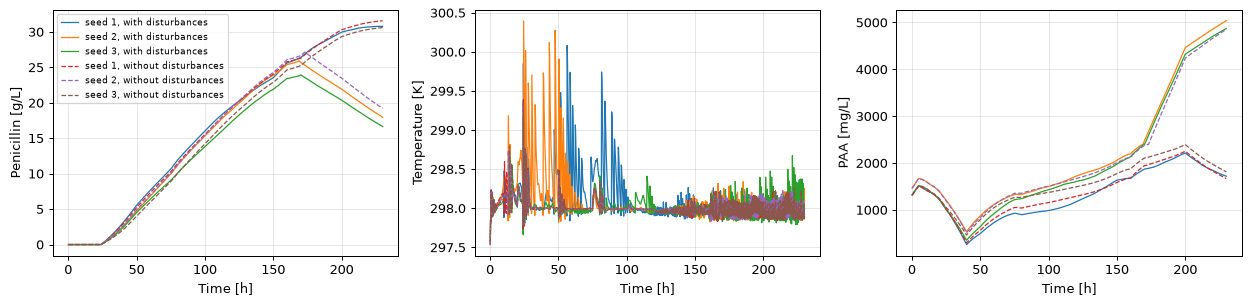

In [2]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.5), sharex=True)
for disturbances, style in ((True, "-"), (False, "--")):
    for seed in (1, 2, 3):
        res = Simulator(config=SimulationConfig(disturbances=disturbances, raman_mode=RamanMode.OFF)).run(seed=seed)
        label = f"seed {seed}, {'with' if disturbances else 'without'} disturbances"
        axes[0].plot(res.time, res["P"], style, lw=1, label=label)
        axes[1].plot(res.time, res["T"], style, lw=1)
        axes[2].plot(res.time, res["PAA"], style, lw=1)
for ax, lab in zip(axes, ["Penicillin [g/L]", "Temperature [K]", "PAA [mg/L]"]):
    ax.set(xlabel="Time [h]", ylabel=lab)
axes[0].legend(fontsize=7)
fig.tight_layout()

## Faults

`SimulationConfig(fault=...)` adds one of IndPenSim's process faults. The channel `Fault_ref` is 1 in the samples
where the fault acts, which gives you labels for fault detection.

In [3]:
for f in Fault:
    print(f.value, f.name)

0 NONE
1 AERATION
2 PRESSURE
3 SUBSTRATE_FEED
4 BASE_FLOW
5 COOLANT_FLOW
6 ALL
7 TEMPERATURE_SENSOR
8 PH_SENSOR


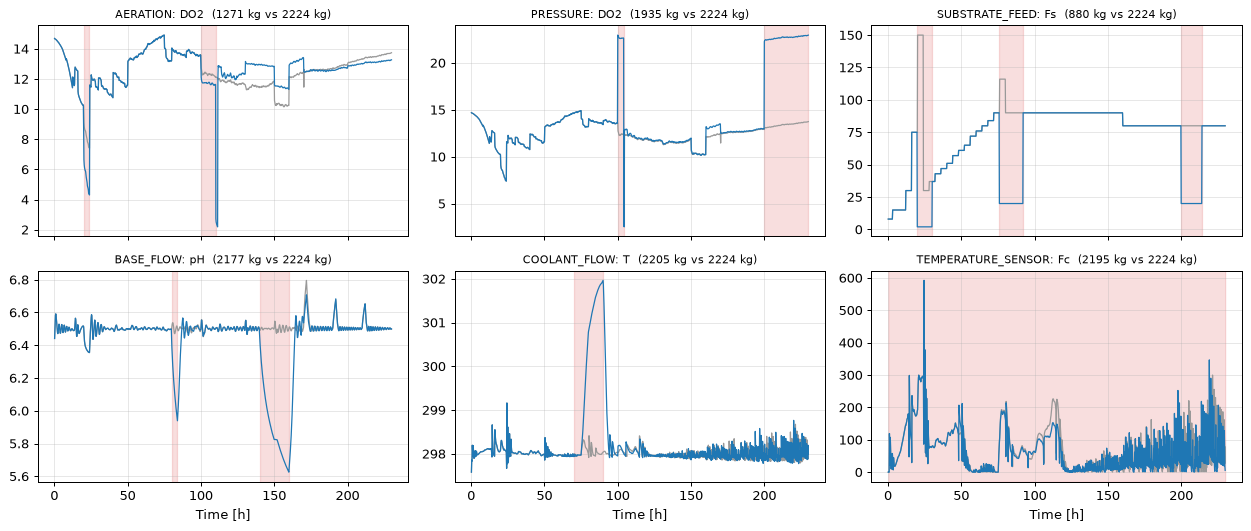

In [4]:
show = {
    Fault.AERATION: "DO2",
    Fault.PRESSURE: "DO2",
    Fault.SUBSTRATE_FEED: "Fs",
    Fault.BASE_FLOW: "pH",
    Fault.COOLANT_FLOW: "T",
    Fault.TEMPERATURE_SENSOR: "Fc",
}
nominal = Simulator(config=SimulationConfig(raman_mode=RamanMode.OFF)).run(seed=3)
fig, axes = plt.subplots(2, 3, figsize=(14, 6), sharex=True)
for ax, (fault, channel) in zip(axes.flat, show.items()):
    res = Simulator(config=SimulationConfig(fault=fault, raman_mode=RamanMode.OFF)).run(seed=3)
    ax.plot(nominal.time, nominal[channel], color="0.6", lw=1, label="nominal")
    ax.plot(res.time, res[channel], lw=1, label=fault.name)
    active = res["Fault_ref"] > 0
    ax.fill_between(res.time, 0, 1, where=active, transform=ax.get_xaxis_transform(), color="tab:red", alpha=0.15)
    ax.set_title(f"{fault.name}: {channel}  ({res.total_yield:.0f} kg vs {nominal.total_yield:.0f} kg)", fontsize=9)
for ax in axes[1]:
    ax.set_xlabel("Time [h]")
fig.tight_layout()

Shaded: samples with `Fault_ref = 1`. Several faults barely change the yield; a monitoring model has to find them in
the online data. [Faults and disturbances](../faults.md) lists the profile of every fault.

## Setpoints and batch length

In [5]:
for tsp in (296.0, 298.0, 300.0):
    res = Simulator(config=SimulationConfig(temperature_setpoint=tsp, raman_mode=RamanMode.OFF)).run(seed=1)
    print(f"temperature setpoint {tsp:.0f} K: {res.total_yield:5.0f} kg")

long = Simulator(config=SimulationConfig(batch_length_h=280.0, raman_mode=RamanMode.OFF)).run(seed=1)
print(f"280 h batch: {len(long)} samples, {long.total_yield:.0f} kg")

temperature setpoint 296 K:  3678 kg


temperature setpoint 298 K:  3602 kg


temperature setpoint 300 K:  3521 kg


280 h batch: 1400 samples, 4156 kg


## Initial conditions and batch parameters

`Simulator.initial_conditions(seed)` shows what a seed draws. Override any of it with `initial_conditions=` in
`run`.

In [6]:
from penicillium import INITIAL_CONDITIONS

seeded = Simulator.initial_conditions(seed=1)
pd.DataFrame(
    {
        "description": [description for description, _ in INITIAL_CONDITIONS.values()],
        "unit": [unit for _, unit in INITIAL_CONDITIONS.values()],
        "seed 1": [seeded[name] for name in INITIAL_CONDITIONS],
    },
    index=pd.Index(list(INITIAL_CONDITIONS), name="name"),
).style.format({"seed 1": "{:.4g}"})

,description,unit,seed 1
name,,,
S,Substrate concentration,g/L,0.777
DO2,Dissolved oxygen concentration,mg/L,14.45
X,"Biomass concentration (1/3 growing, 2/3 non-growing regions)",g/L,0.468
V,Volume,L,5.748e+04
Wt,Vessel weight,kg,6.154e+04
pH,pH,-,6.502
T,Temperature,K,296.3
O2,O2 fraction in off-gas,-,0.1607
CO2outgas,CO2 in off-gas,%,0.03831


In [7]:
for mux in (0.36, 0.41, 0.46):
    res = Simulator(config=SimulationConfig(raman_mode=RamanMode.OFF)).run(seed=5, initial_conditions={"mu_x_max": mux})
    print(f"mu_x_max = {mux}: {res.total_yield:.0f} kg")

mu_x_max = 0.36: 2521 kg


mu_x_max = 0.41: 2334 kg


mu_x_max = 0.46: 2211 kg


`BatchParameters` holds everything random about a batch: initial state, kinetic parameters and the eight disturbance
sequences. Build it from a seed, edit it, and replay the batch with exactly those draws.

disturbances: ['distMuP', 'distMuX', 'distcs', 'distcoil', 'distabc', 'distPAA', 'distTcin', 'distO_2in']


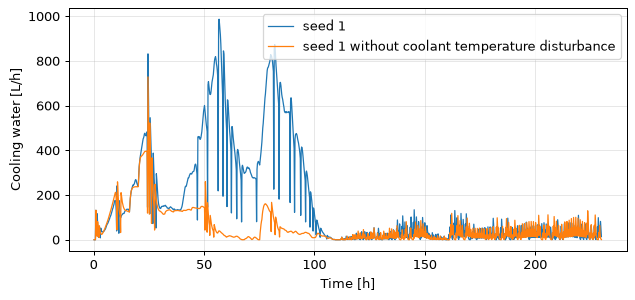

In [8]:
bp = BatchParameters.from_seed(1)
print("disturbances:", list(bp.disturbances))

bp.disturbances["distTcin"][:] = 0.0  # this batch, without the coolant temperature disturbance
cfg = SimulationConfig(raman_mode=RamanMode.OFF)
edited = Simulator(config=cfg).run(batch_parameters=bp)
original = Simulator(config=cfg).run(seed=1)

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(original.time, original["Fc"], lw=1, label="seed 1")
ax.plot(edited.time, edited["Fc"], lw=1, label="seed 1 without coolant temperature disturbance")
ax.set(xlabel="Time [h]", ylabel="Cooling water [L/h]")
ax.legend();

All options are described in [Simulation options](../configuration.md).

**Next:** [Lab data, Raman spectra and measurement noise](04_lab_data_raman_and_noise.ipynb).